<a href="https://colab.research.google.com/github/azhongai666/AI_code_pulich/blob/main/261119_YOLO%E5%85%A5%E9%97%A8_%E8%AE%AD%E7%BB%83%E5%AE%98%E7%BD%91%E6%95%B0%E6%8D%AE%E9%9B%86.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Fri Nov 20 15:17:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 环境安装

In [2]:

!uv pip install ultralytics
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


# 导入python包

In [3]:
from ultralytics import YOLO

from IPython.display import display, Image

# 用预训练模型测试单张图片

## 命令行格式预测

In [15]:
!yolo task=detect mode=predict model=yolo26n.pt conf=0.5 source='https://media.roboflow.com/notebooks/examples/dog.jpeg' save=True

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs

Found https://media.roboflow.com/notebooks/examples/dog.jpeg locally at dog.jpeg
image 1/1 /content/dog.jpeg: 640x384 1 person, 1 dog, 9.9ms
Speed: 41.7ms preprocess, 9.9ms inference, 12.8ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /content/runs/detect/predict-3
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [16]:
pwd

'/content'

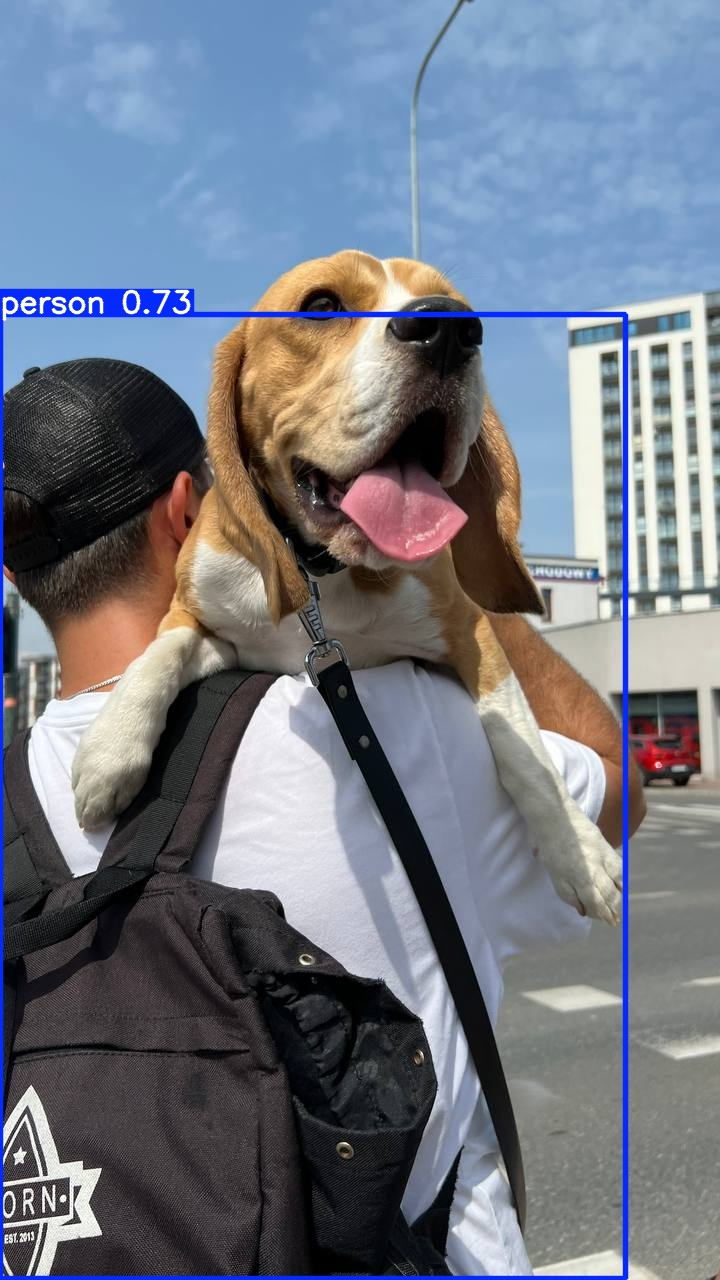

In [17]:
Image(filename='runs/detect/predict/dog.jpg', height=600)

## Python代码预测


In [18]:
model = YOLO(f'yolo26n.pt')
results = model.predict(source='https://media.roboflow.com/notebooks/examples/dog.jpeg', conf=0.25)


Found https://media.roboflow.com/notebooks/examples/dog.jpeg locally at dog.jpeg
image 1/1 /content/dog.jpeg: 640x384 1 person, 1 dog, 1 backpack, 11.1ms
Speed: 1.8ms preprocess, 11.1ms inference, 4.2ms postprocess per image at shape (1, 3, 640, 384)


In [19]:
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

In [20]:
results[0].boxes.xyxy

tensor([[  64.3950,  250.0124,  644.6239,  934.7677],
        [   0.0000,  359.0189,  584.8723, 1280.0000],
        [   0.0000,  584.0991,  536.6089, 1277.0442]], device='cuda:0')

In [21]:
results[0].boxes.conf

tensor([0.7836, 0.5764, 0.2891], device='cuda:0')

In [22]:
results[0].boxes.cls

tensor([16.,  0., 24.], device='cuda:0')

# coco8数据集模型训练

In [23]:
%cd /content

/content


In [24]:
from ultralytics import YOLO

from IPython.display import display, Image

## yolov3

In [25]:
# !yolo task=detect mode=train model=/content/ultralytics/ultralytics/cfg/models/v3/yolov3.yaml data='coco8.yaml' epochs=3 imgsz=640 plots=True
!yolo task=detect mode=train model=yolov3.pt data='coco8.yaml' epochs=2 imgsz=640 plots=True

PRO TIP 💡 Replace 'model=yolov3.pt' with new 'model=yolov3u.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, 

## yolov5

In [26]:

!yolo task=detect mode=train model=yolov5n.yaml data='coco8.yaml' epochs=2 imgsz=640 plots=True
# !yolo task=detect mode=train model=yolov5n.pt data={dataset.location}/data.yaml epochs=2 imgsz=640 plots=True

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov5n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

## detr

In [27]:
!yolo train model=rtdetr-l.pt data=coco8.yaml epochs=3 imgsz=640
# !yolo task=detect mode=train model=rtdetr-l.pt data={dataset.location}/data.yaml epochs=2 imgsz=640 plots=True


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

## yolov8

In [ ]:
!yolo task=detect mode=train model=yolov8s.pt data='coco8.yaml' epochs=3 imgsz=640 plots=True


## yolov26

In [30]:
!yolo task=detect mode=train model=yolo26n.yaml data='coco8.yaml' epochs=3 imgsz=640 plots=True

# !yolo task=detect mode=train model=yolo26n.pt data='coco8.yaml' epochs=3 imgsz=640 plots=True


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-6, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

# HomeObjects-3K数据集模型训练

## yolov8

In [ ]:
# "HomeObjects-3K.yaml"

In [31]:
!yolo task=detect mode=train model=yolov8n.pt data='HomeObjects-3K.yaml' epochs=3 imgsz=640 plots=True


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=HomeObjects-3K.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-7, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

## yolov26

In [32]:
# !yolo task=detect mode=train model=yolo26n.yaml data='HomeObjects-3K.yaml' epochs=3 imgsz=640 plots=True

!yolo task=detect mode=train model=yolo26n.pt data='HomeObjects-3K.yaml' epochs=2 imgsz=640 plots=True


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=HomeObjects-3K.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-8, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

# 模型评估

In [33]:
!yolo task=detect mode=val model=/content/runs/detect/train-8/weights/best.pt data=HomeObjects-3K.yaml


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2592.3±810.9 MB/s, size: 134.9 KB)
val: Scanning /content/datasets/homeobjects-3K/labels/val.cache... 404 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 404/404 73.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 3.9it/s 6.7s
                   all        404       3470      0.597      0.564      0.614      0.425
                   bed         22         22      0.543      0.682       0.77      0.553
                  sofa        286        398      0.773      0.796      0.858      0.626
                 chair        154        305      0.555      0.669      0.682      0.465
                 table        300        469      0.645      0.705      0.734      0.523
                  lamp        

# 模型预测

In [34]:
!yolo task=detect mode=predict model=/content/runs/detect/train-8/weights/best.pt conf=0.25 source=/content/datasets/homeobjects-3K/images/val save=True

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs

image 1/404 /content/datasets/homeobjects-3K/images/val/living_room_10.jpg: 640x448 1 sofa, 1 table, 2 potted plants, 11.7ms
image 2/404 /content/datasets/homeobjects-3K/images/val/living_room_1000.jpg: 640x640 1 sofa, 3 chairs, 2 tables, 1 lamp, 2 windows, 1 photo frame, 31.3ms
image 3/404 /content/datasets/homeobjects-3K/images/val/living_room_1004.jpg: 640x480 1 sofa, 28.6ms
image 4/404 /content/datasets/homeobjects-3K/images/val/living_room_1008.jpg: 448x640 1 sofa, 1 table, 3 potted plants, 1 photo frame, 28.9ms
image 5/404 /content/datasets/homeobjects-3K/images/val/living_room_1012.jpg: 448x640 2 chairs, 1 table, 1 window, 2 photo frames, 13.8ms
image 6/404 /content/datasets/homeobjects-3K/images/val/living_room_1016.jpg: 448x640 1 sofa, 1 chair, 2 tables, 4 potted plants, 1 photo frame, 14.1ms
image 7/404 /conten

# 显示预测结果

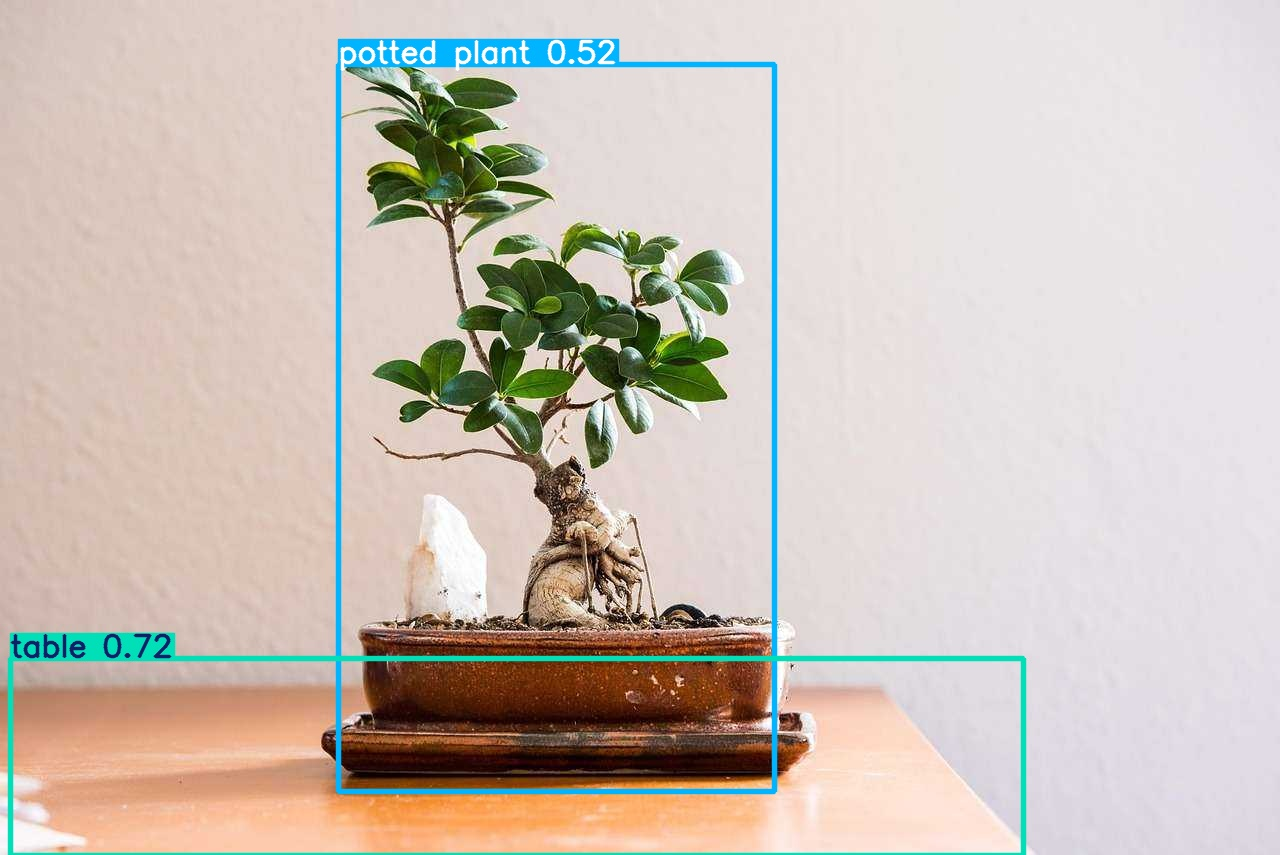

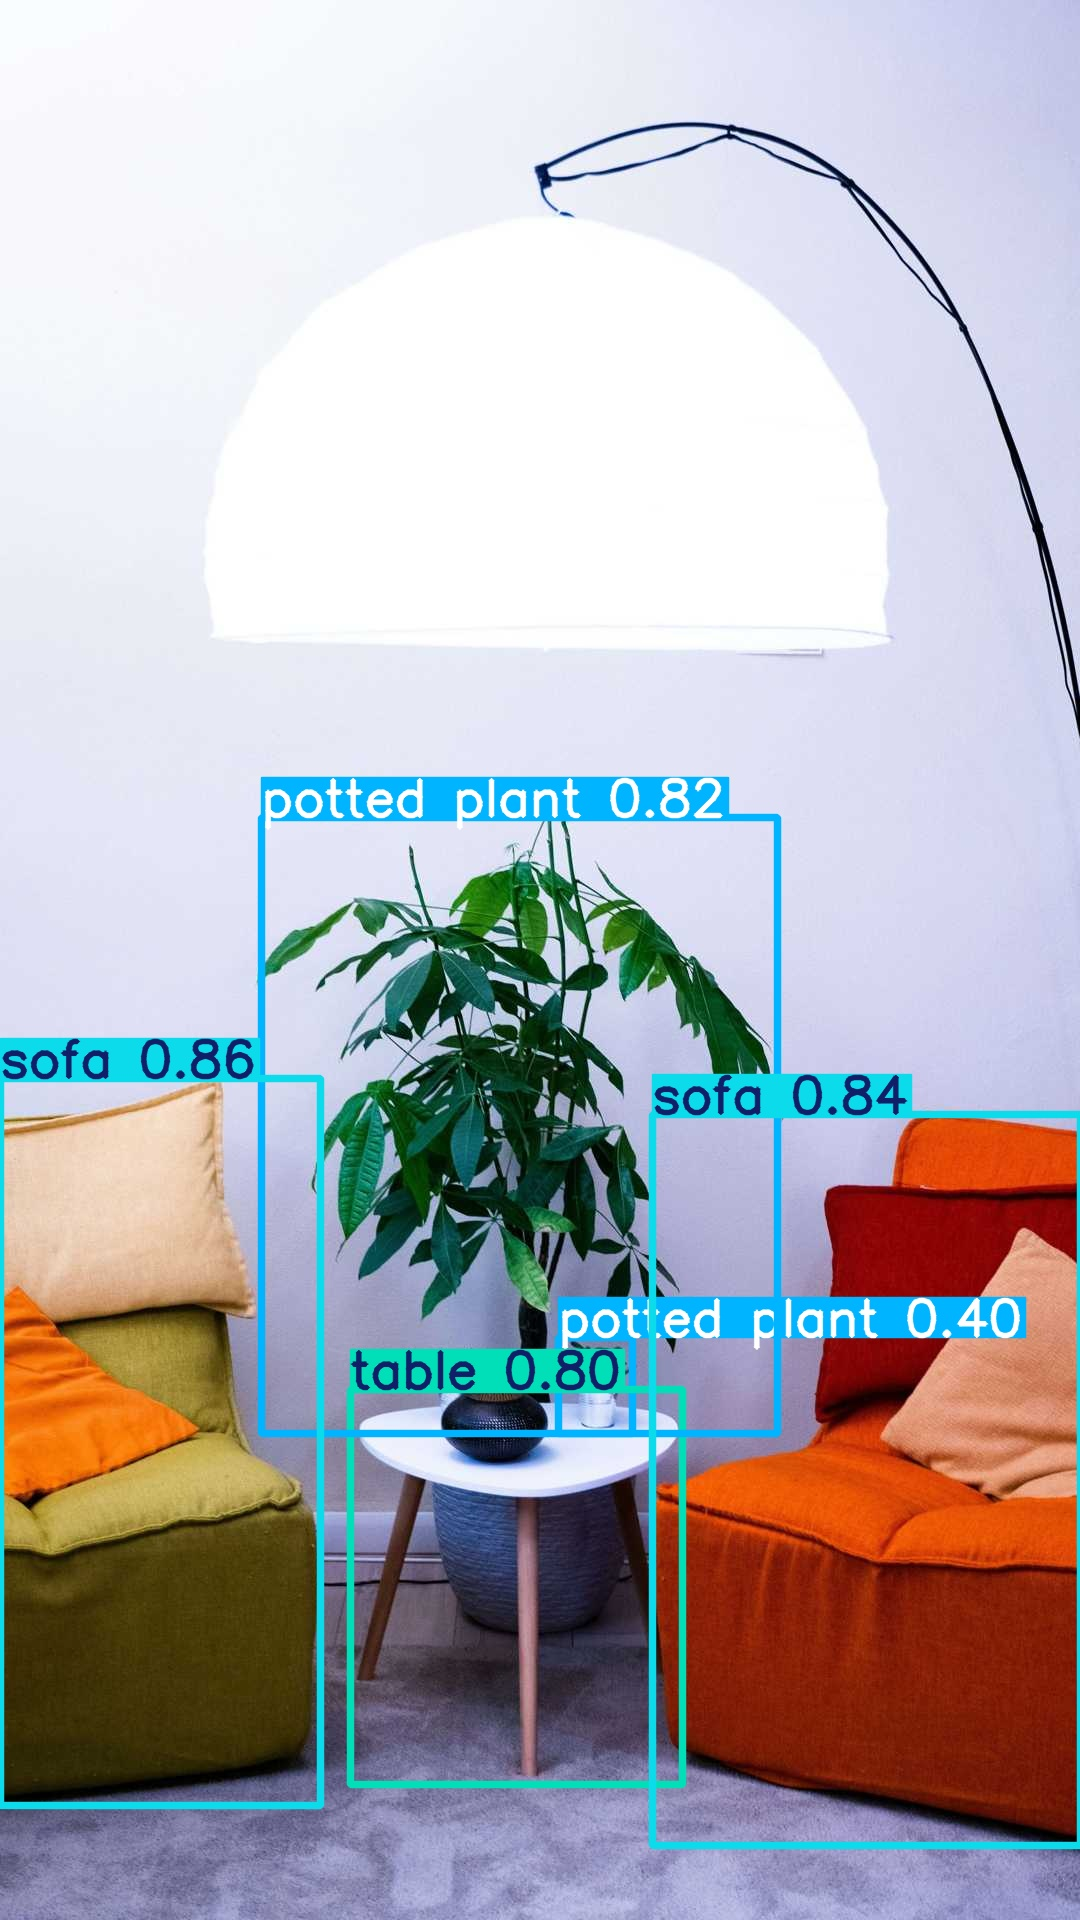

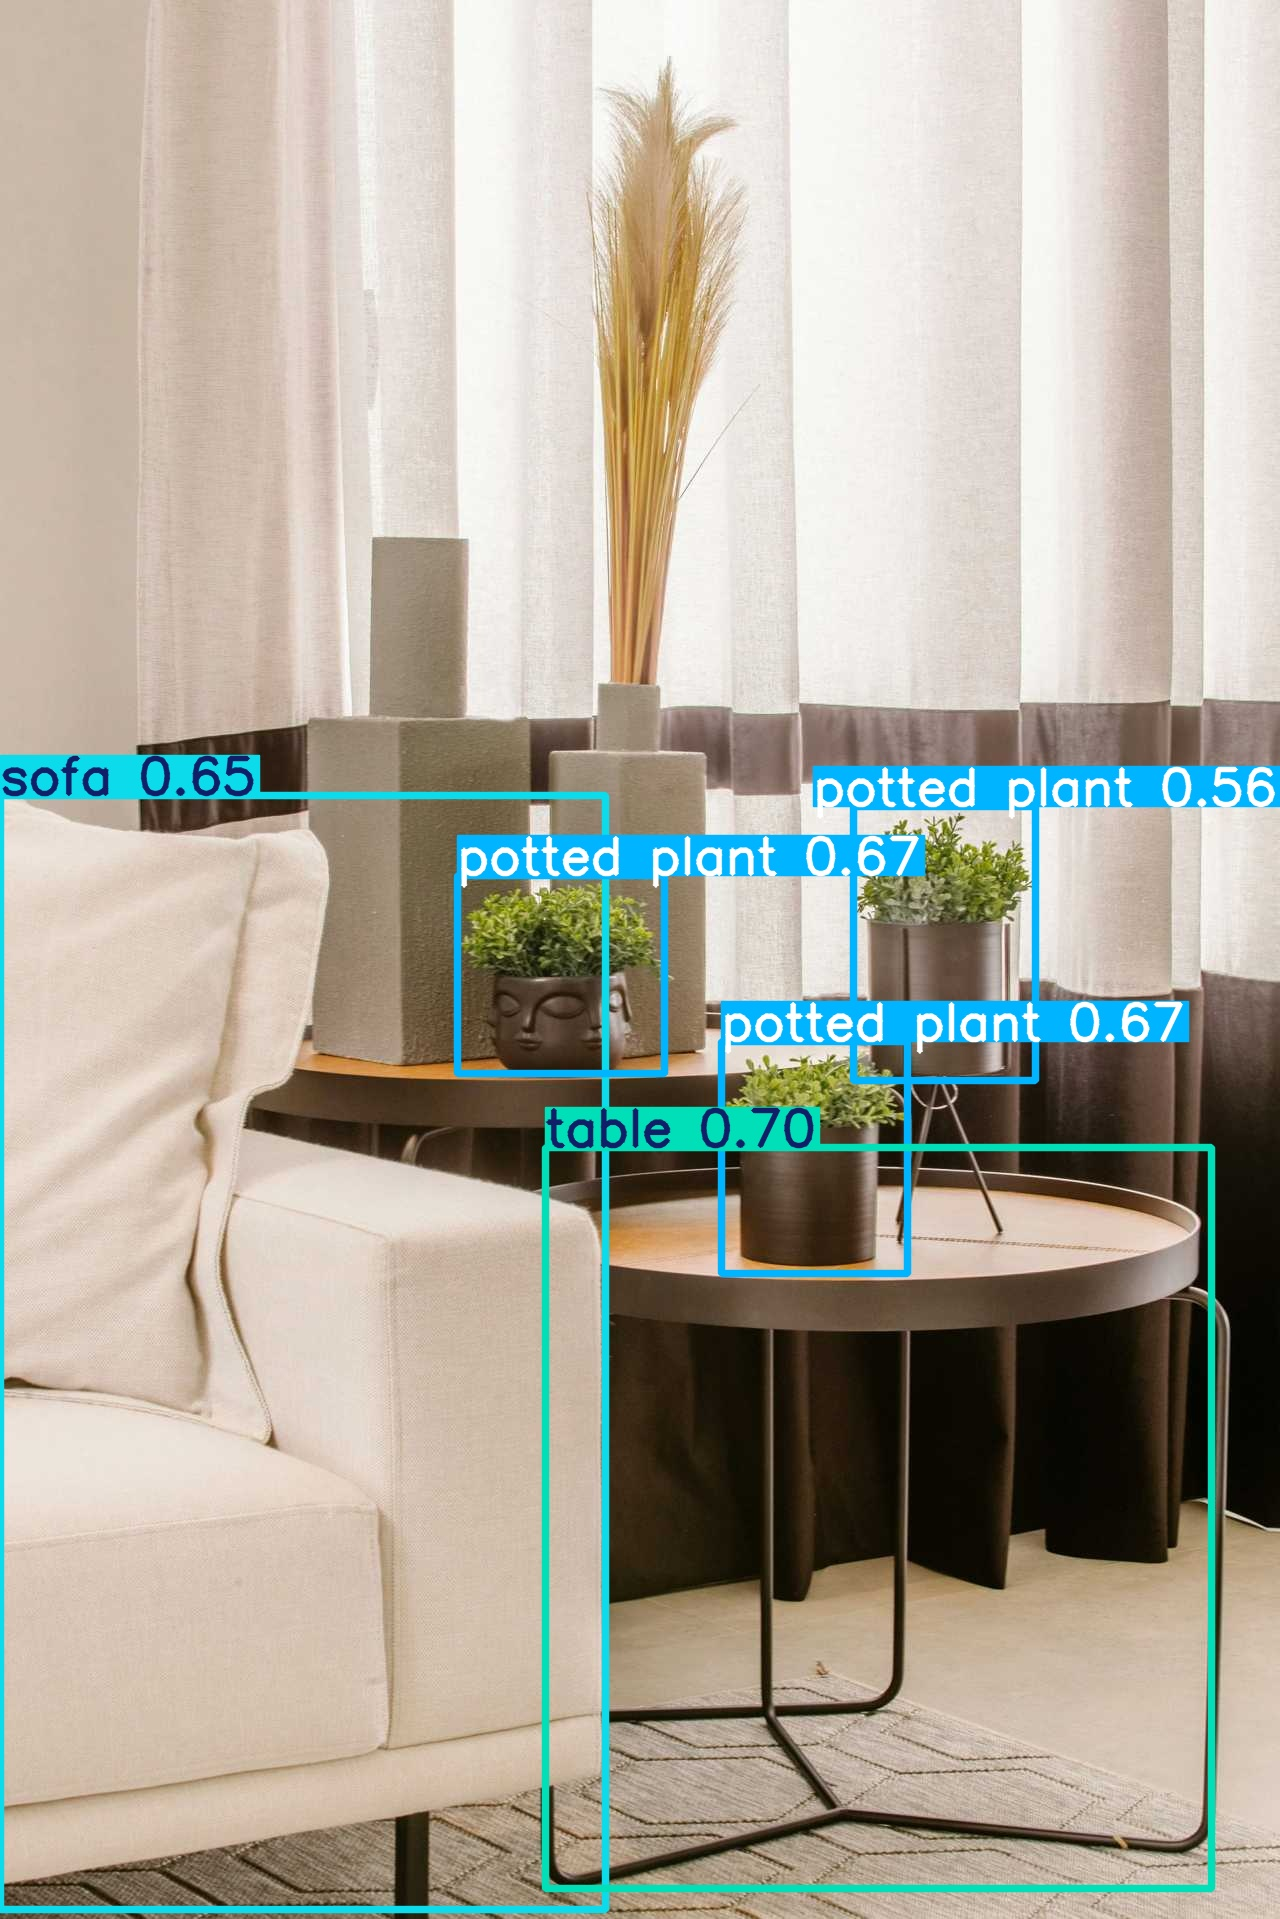

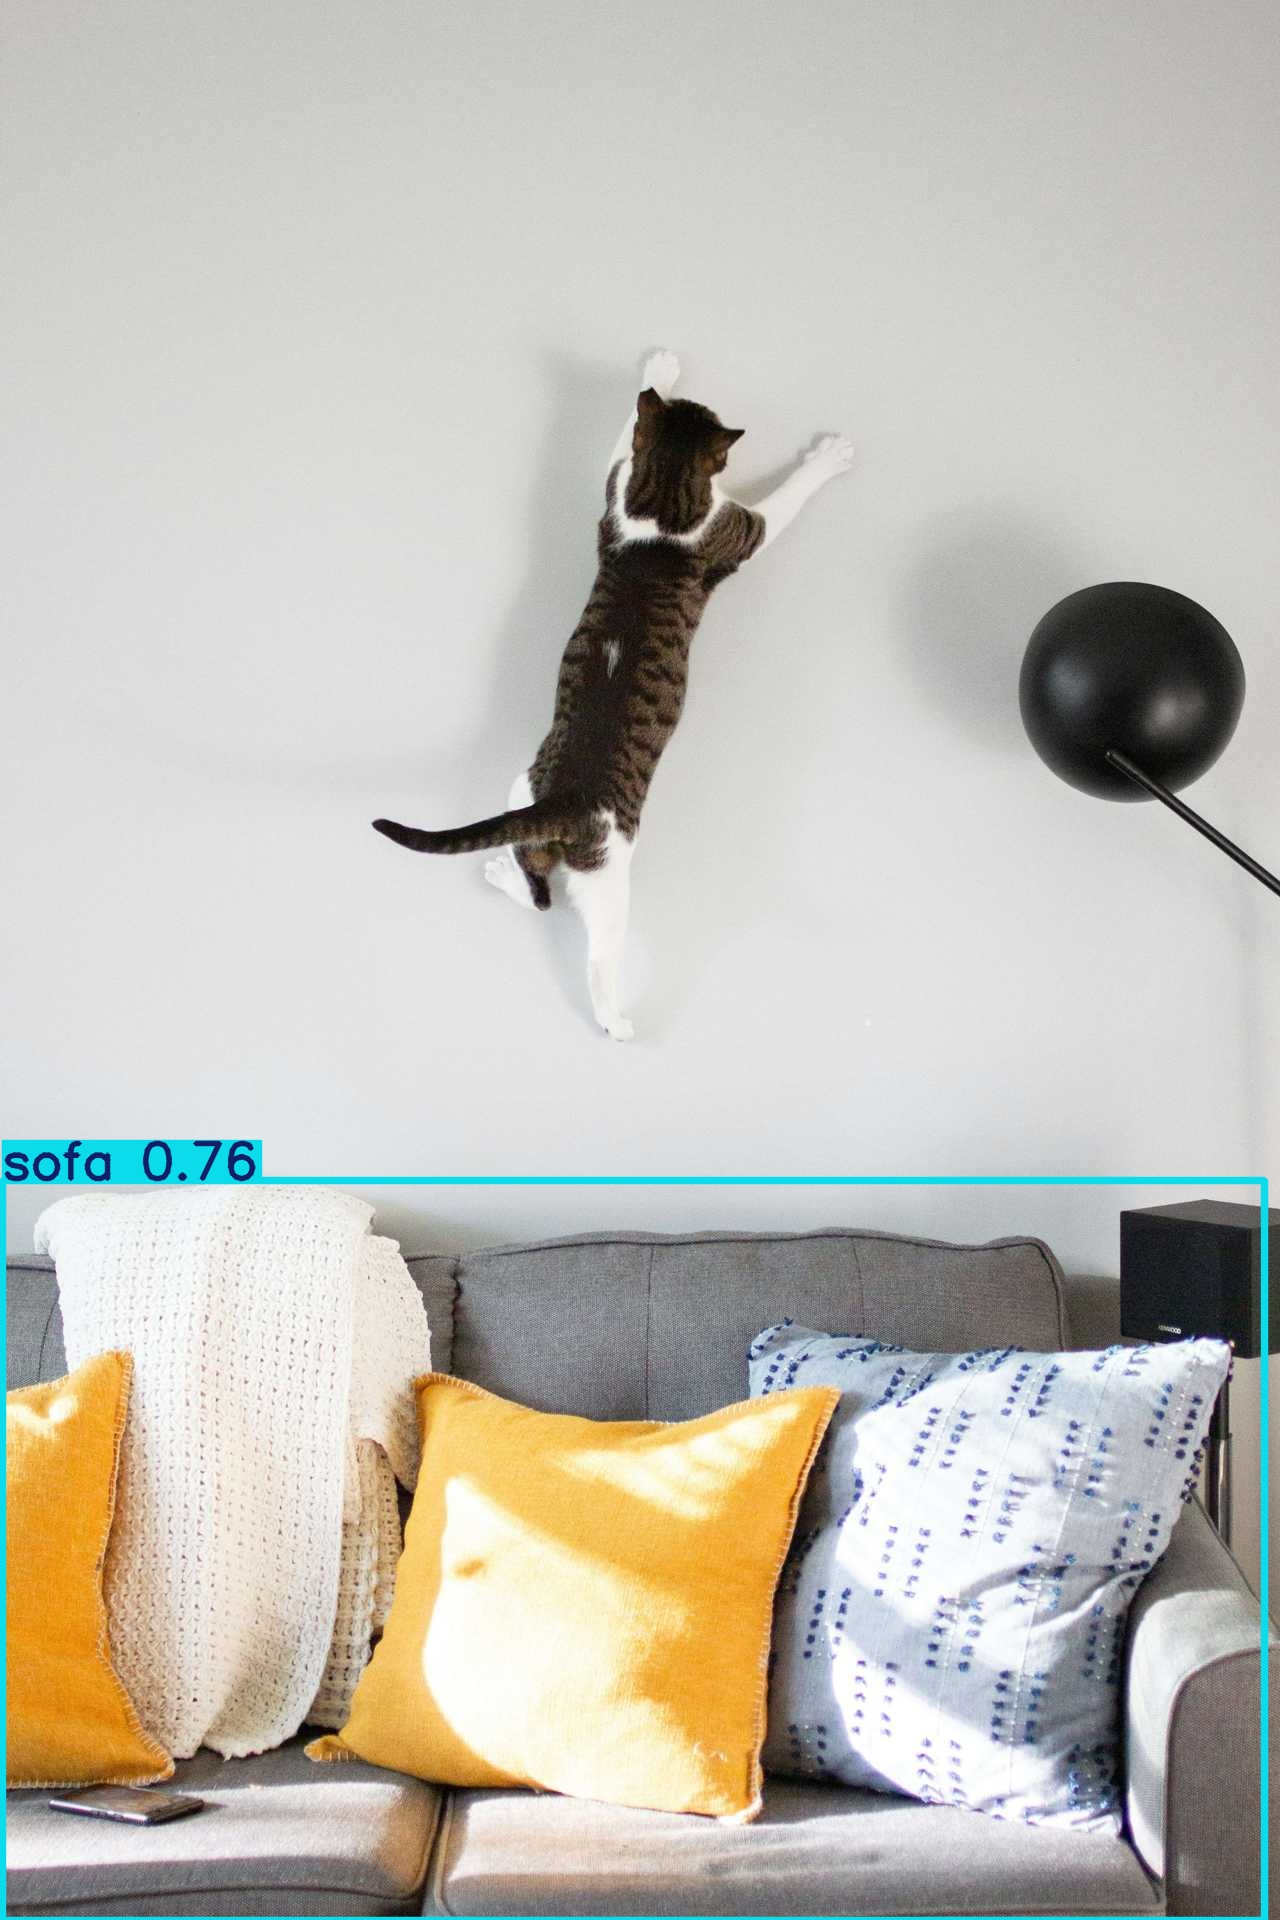

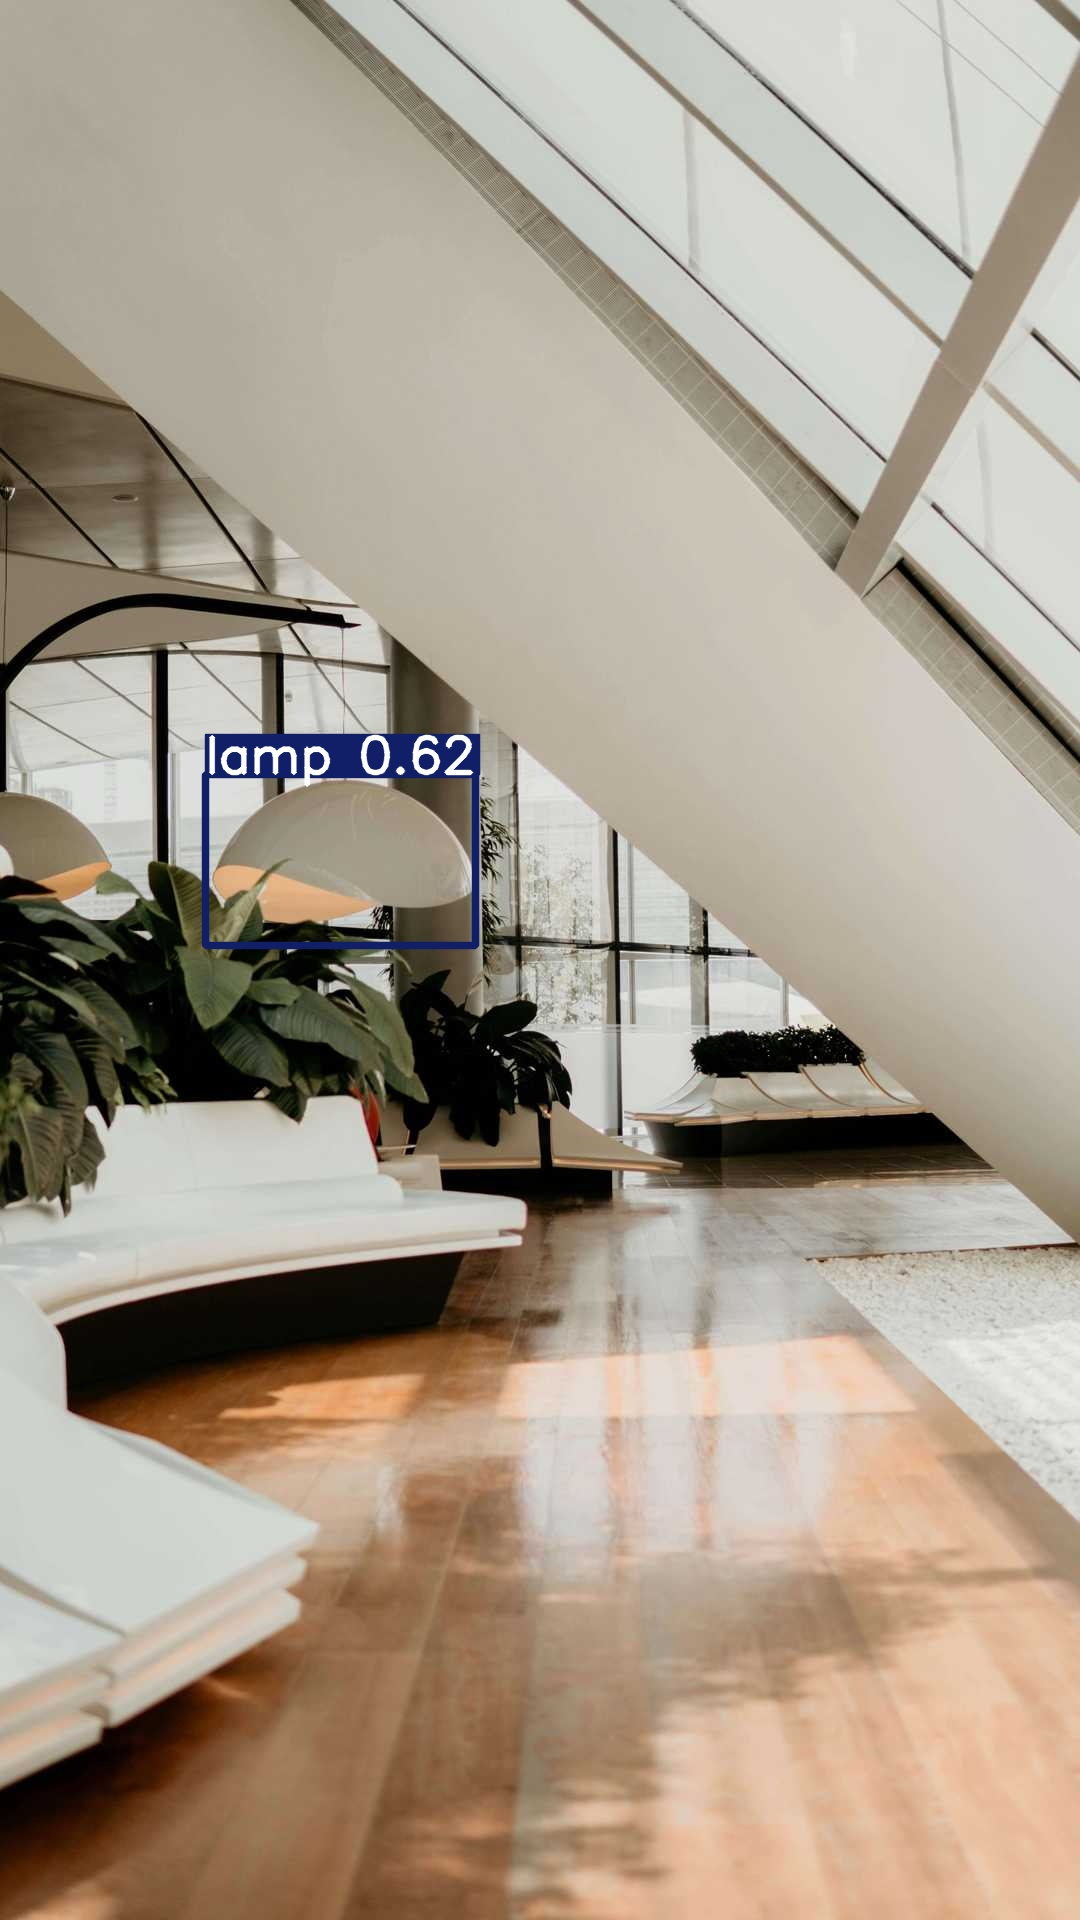

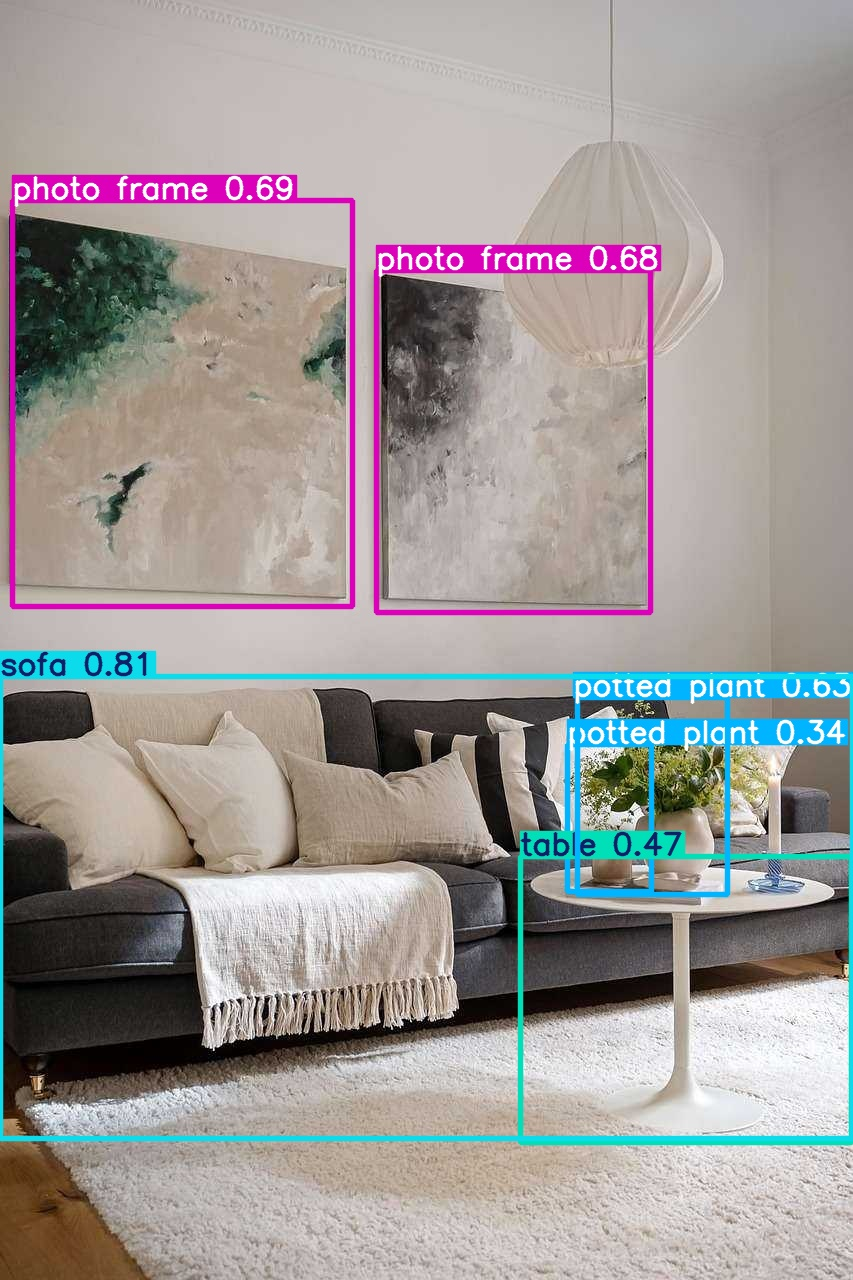

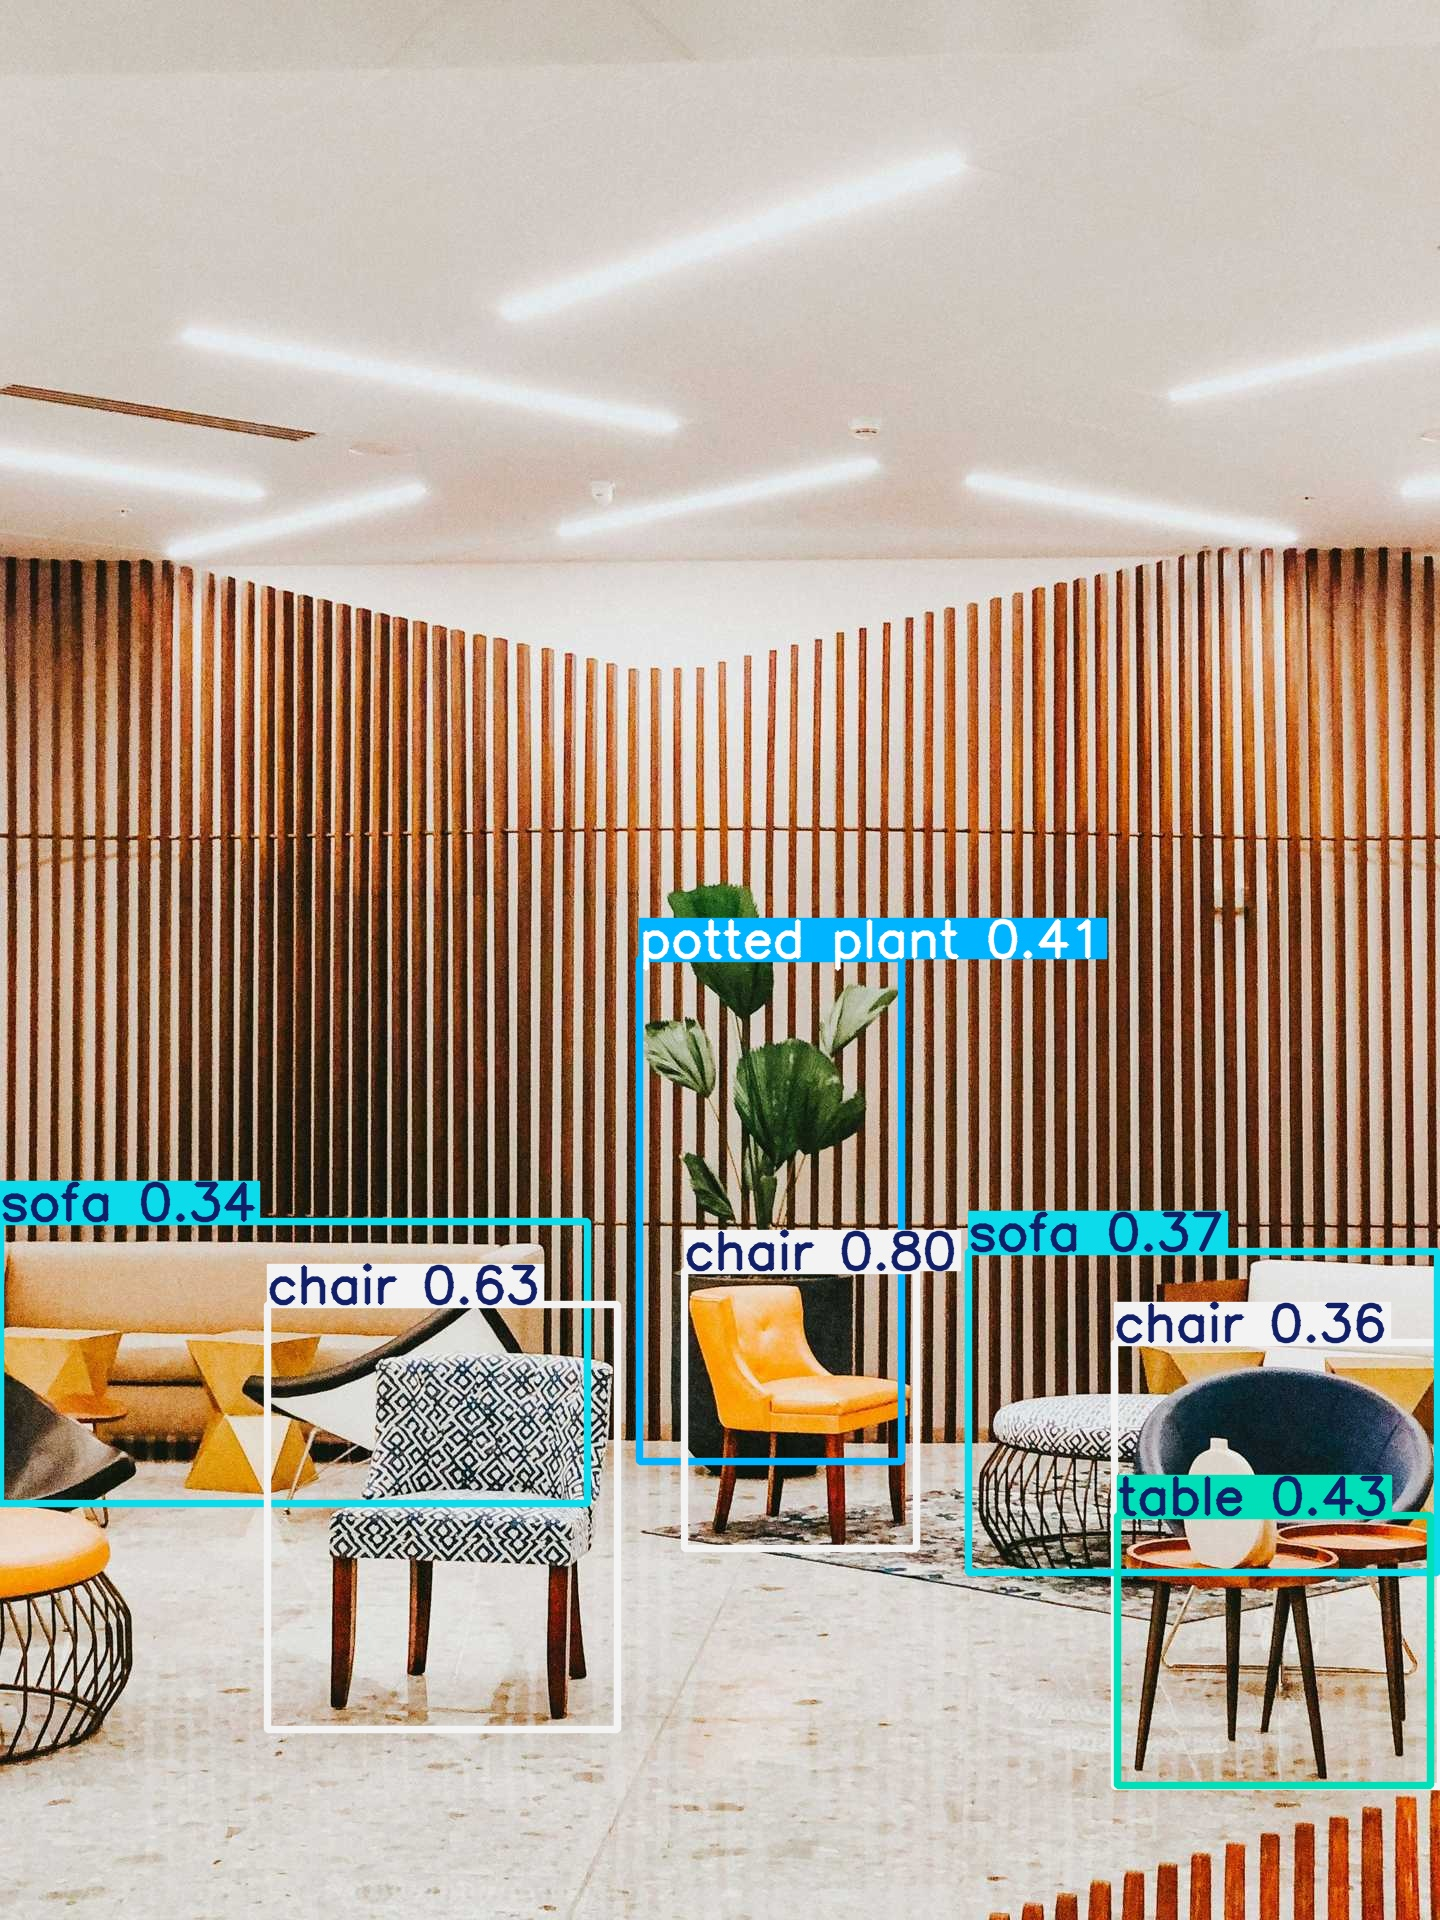

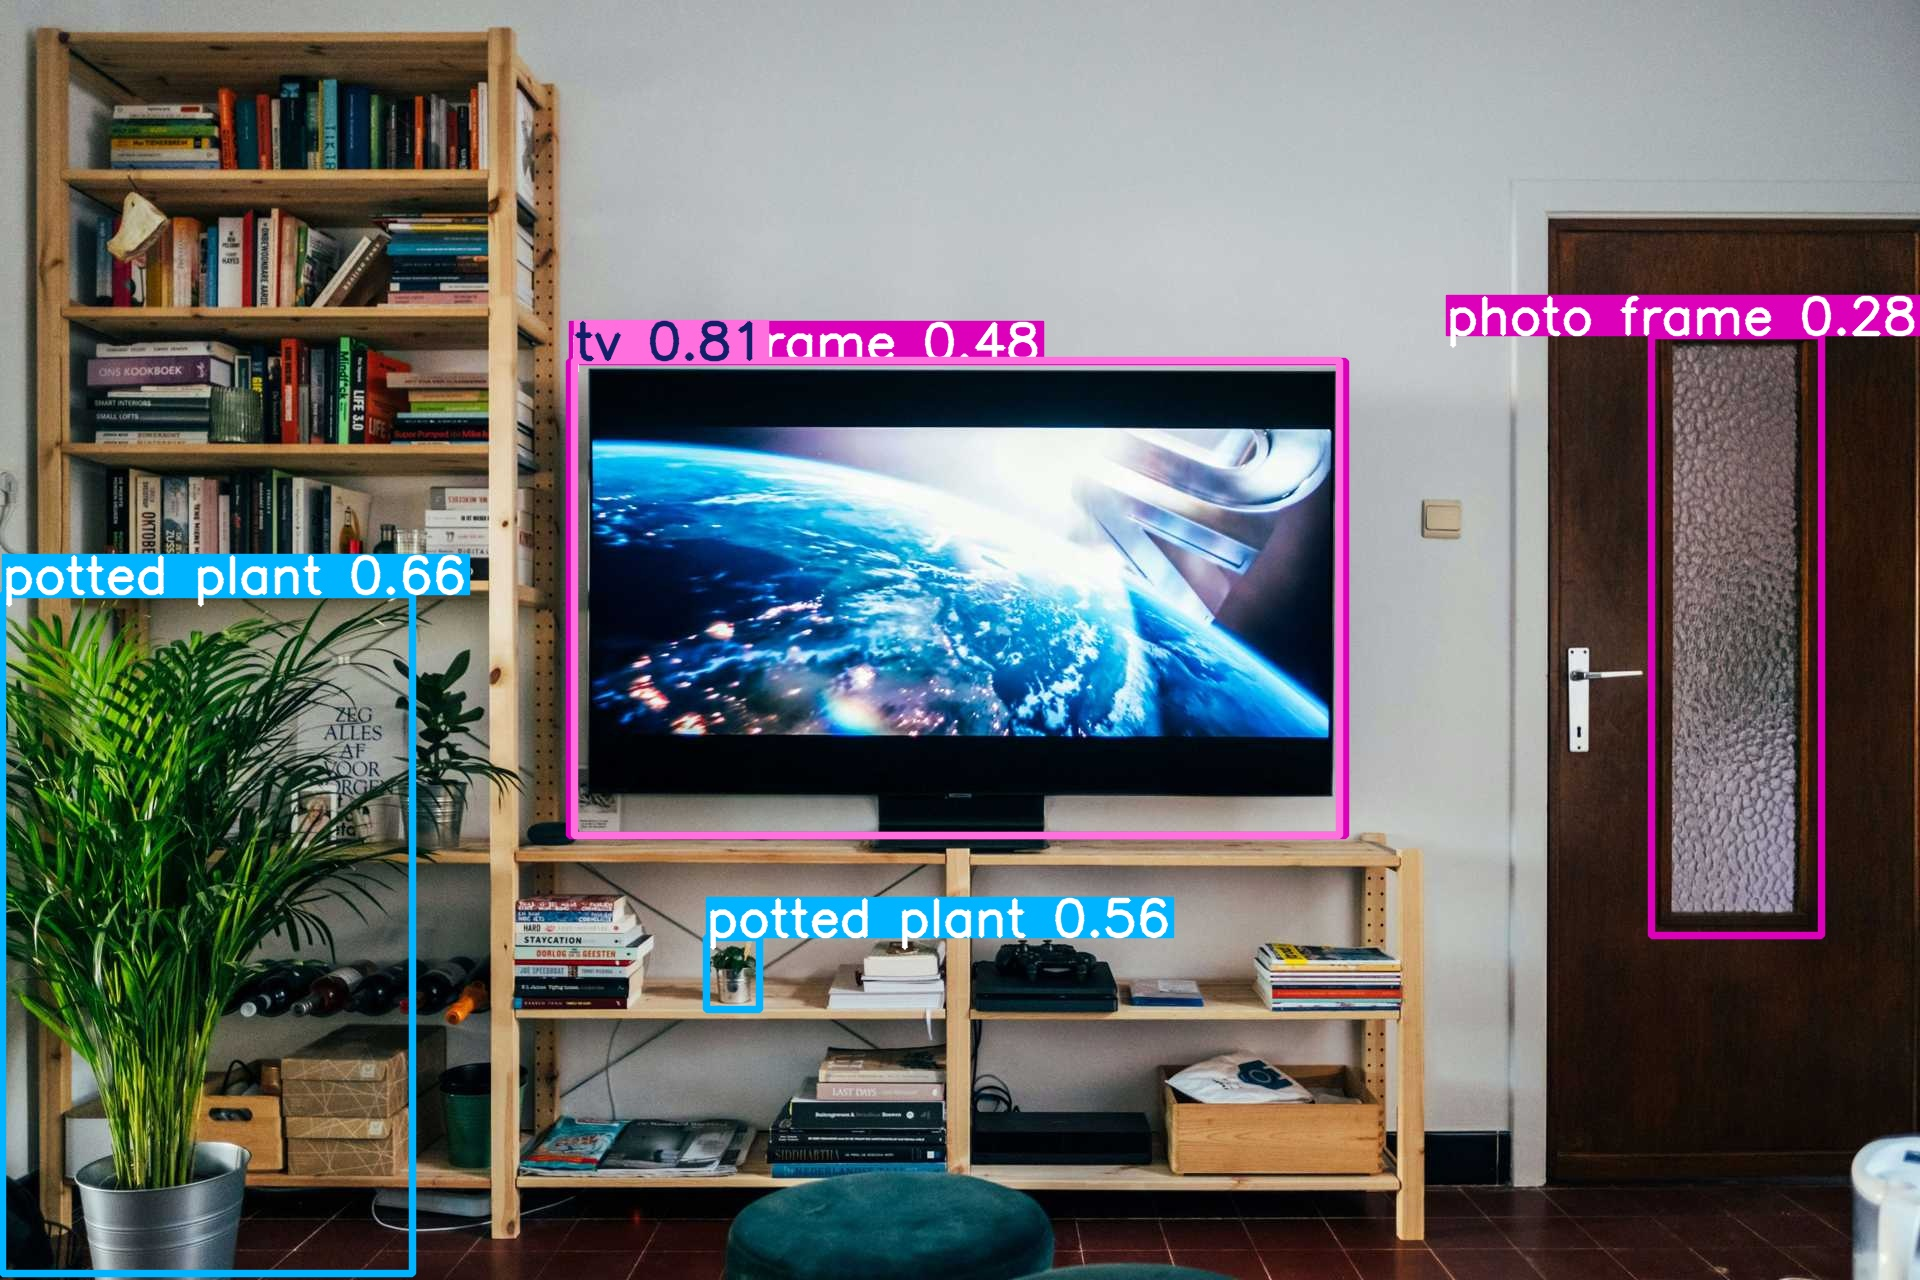

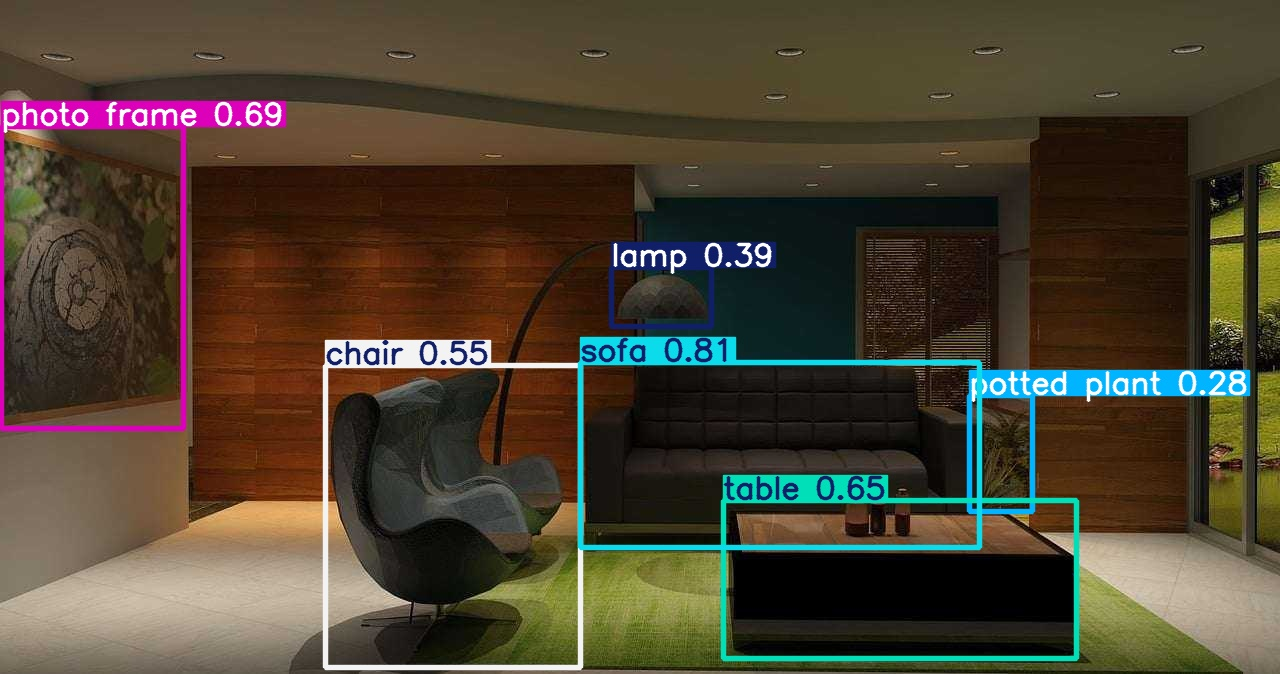

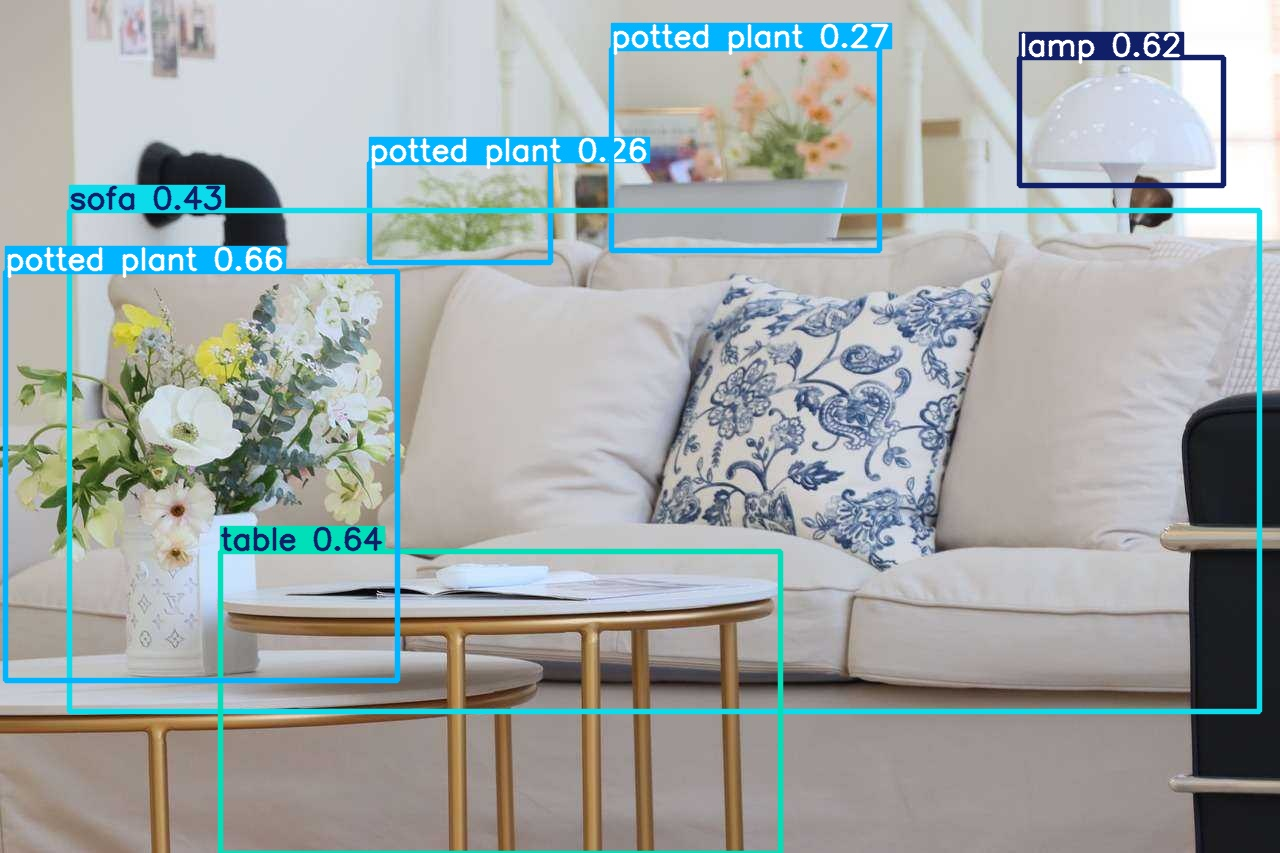

In [35]:
import glob
from IPython.display import Image, display

for image_path in glob.glob('runs/detect/predict-4/*.jpg')[:10]:
      display(Image(filename=image_path, width=600))
      print("\n")